# Example of the aitlas toolbox in the context of object detection 

This notebook shows a sample implementation of object detection using the aitlas toolbox. The RarePlanes dataset contains airplane annotations in geojson and xml format, for real and synthetic imagery respectfully. 

## Import the required packages

In [ ]:
from aitlas.datasets import RarePlanesDataset
from aitlas.transforms import Resize
from aitlas.utils import image_loader
from aitlas.models import FasterRCNN

## Visualize images and objects with bounding boxes

Original train/validation/test splits

In [ ]:
dataset_config = {
    "data_dir": "./data/RarePlanes/synthetic/",
    "task": "train"
}
dataset = RarePlanesDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 45000


In [ ]:
dataset_config = {
    "data_dir": "./data/RarePlanes/real/",
    "task": "train"
}
dataset = RarePlanesDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 5815


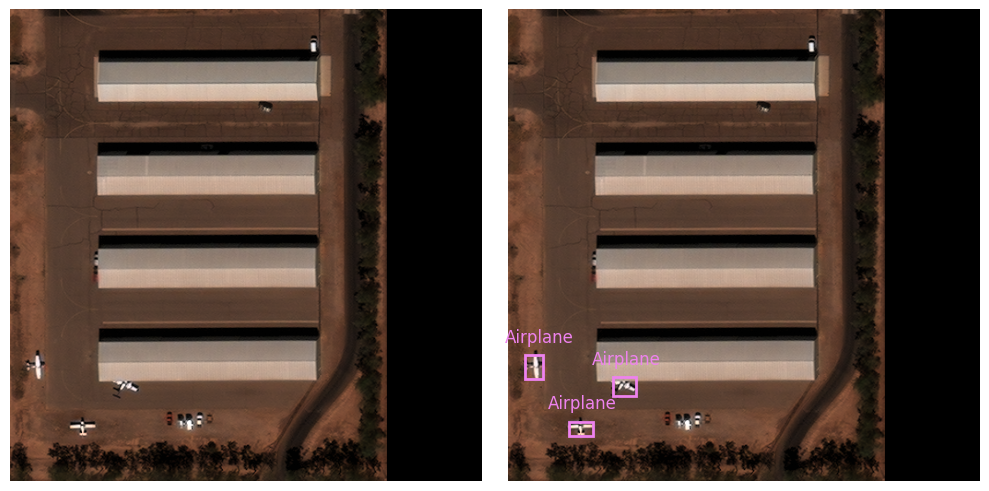

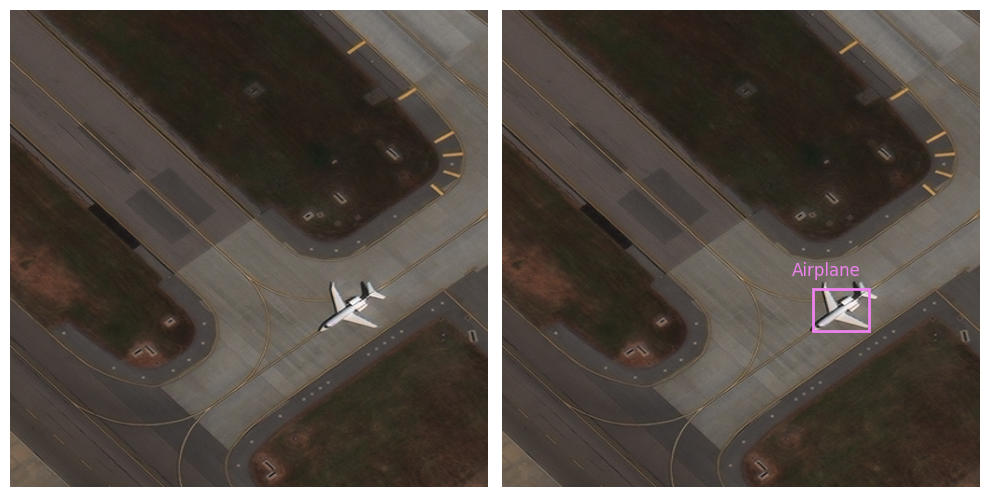

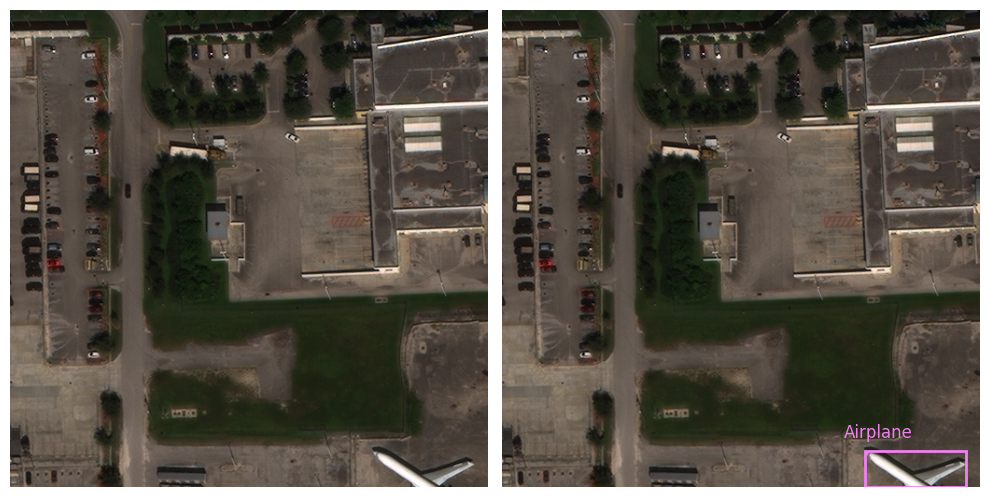

In [21]:
dataset.show_image(50);
dataset.show_image(10);
dataset.show_image(200);

New 60/20/20 splits

Total number of patches: 5115


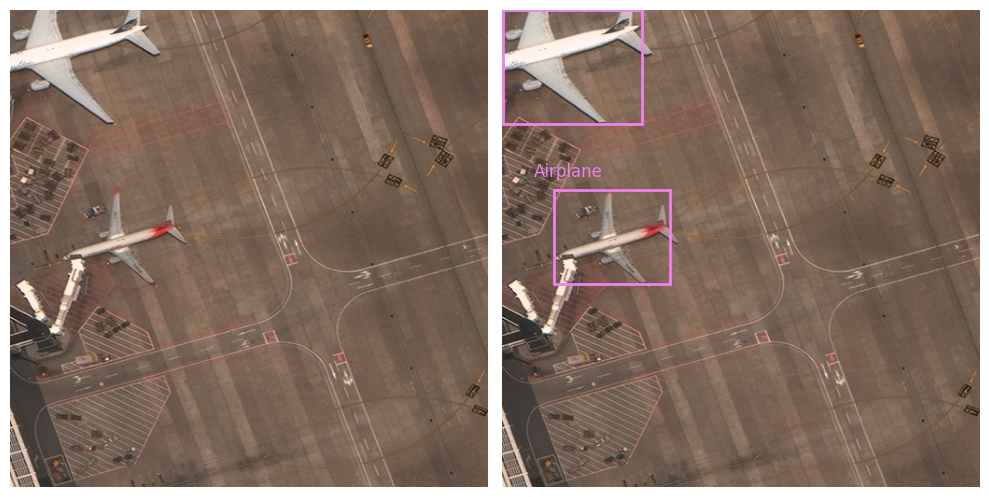

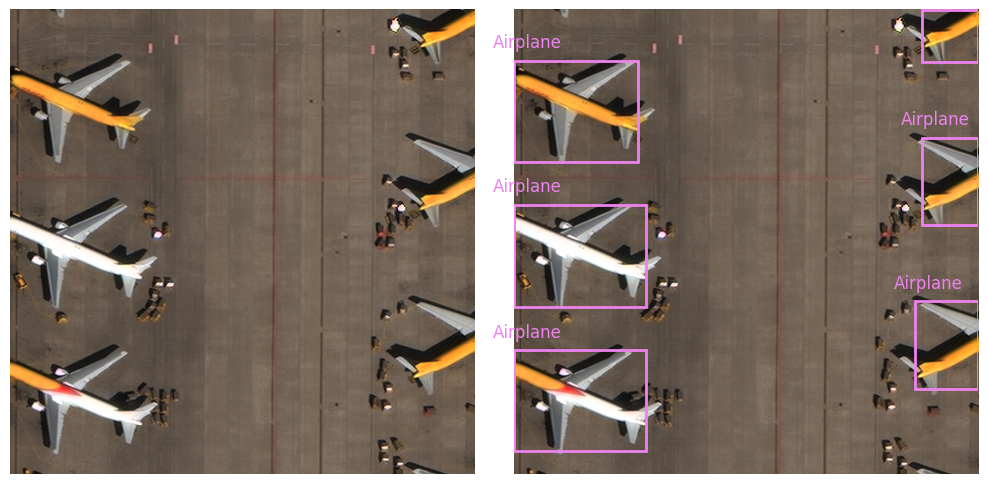

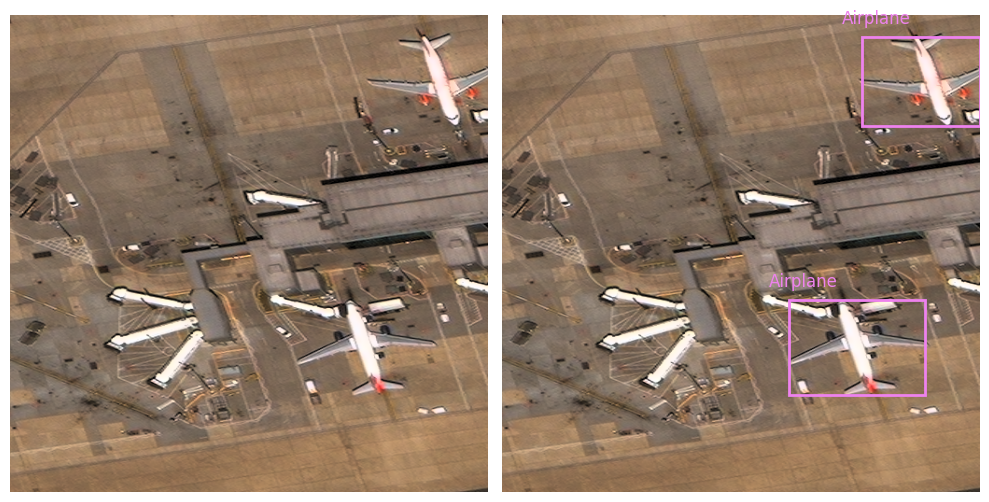

In [ ]:
dataset_config = {
    "data_dir": "./data/RarePlanes/",
    "csv_file": "./data/RarePlanes/rare_planes_train.csv",
    "imagery": "real"
}
dataset = RarePlanesDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

dataset.show_image(50);
dataset.show_image(10);
dataset.show_image(200);

Total number of patches: 30000


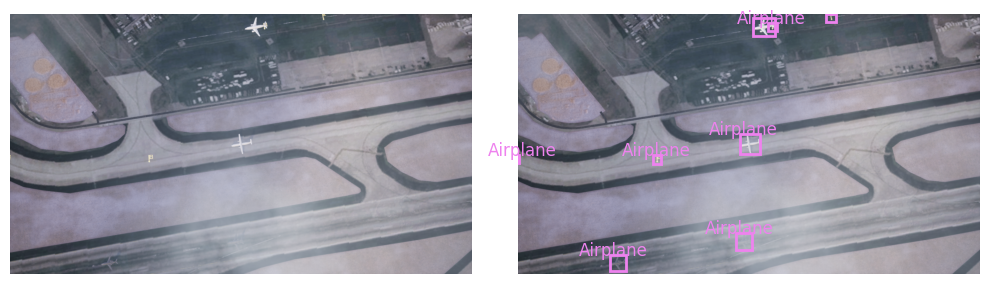

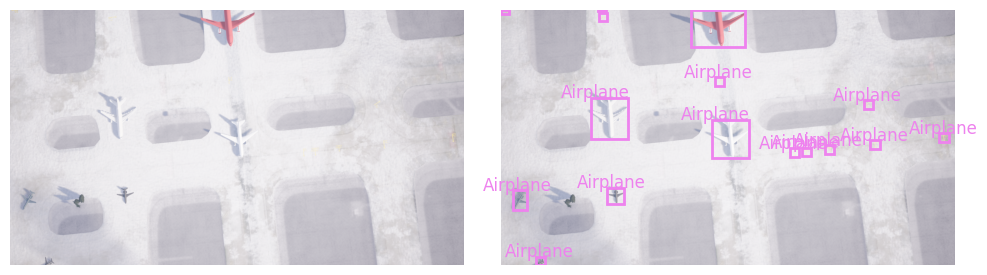

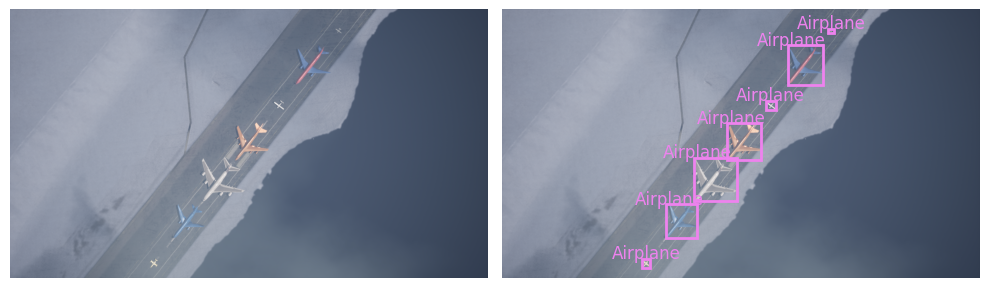

In [ ]:
dataset_config = {
    "data_dir": "./data/RarePlanes/",
    "csv_file": "./data/RarePlanes/rare_planes_train.csv",
    "imagery": "synthetic"
}
dataset = RarePlanesDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

dataset.show_image(50);
dataset.show_image(10);
dataset.show_image(200);

Total number of patches: 35115


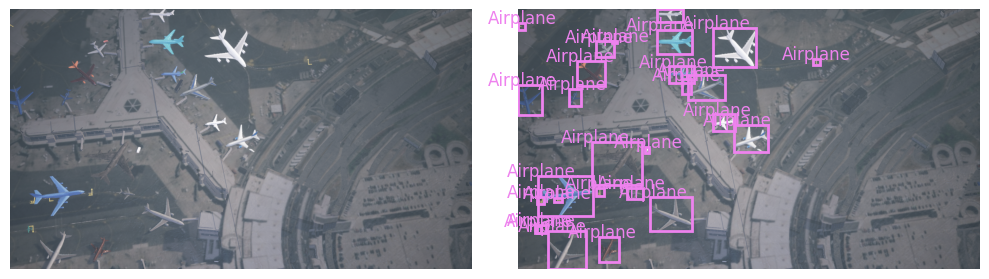

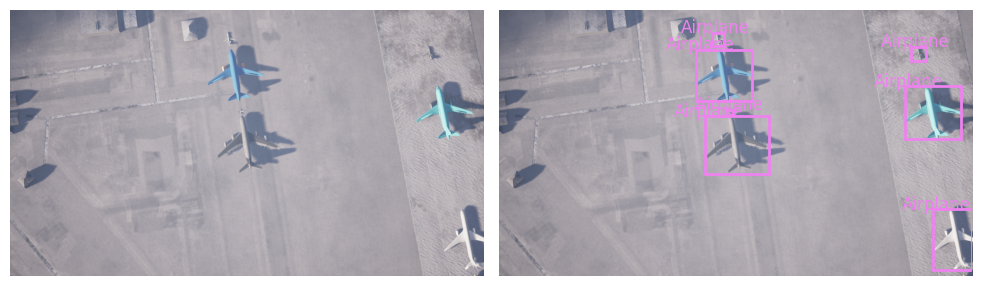

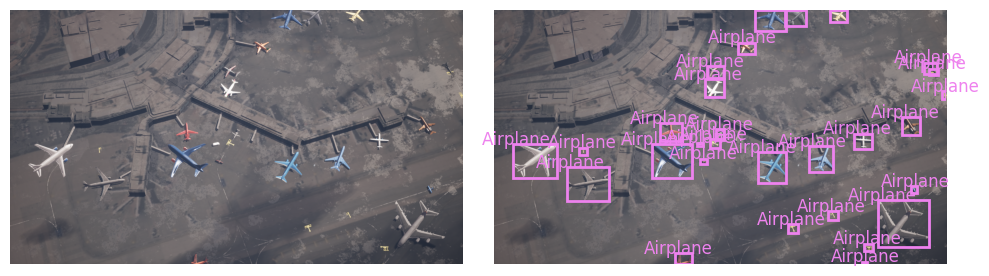

In [ ]:
dataset_config = {
    "data_dir": "./data/RarePlanes/",
    "csv_file": "./data/RarePlanes/rare_planes_train.csv",
    "imagery": "all" # both real and synthetic images
}
dataset = RarePlanesDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

dataset.show_image(50);
dataset.show_image(10);
dataset.show_image(200);

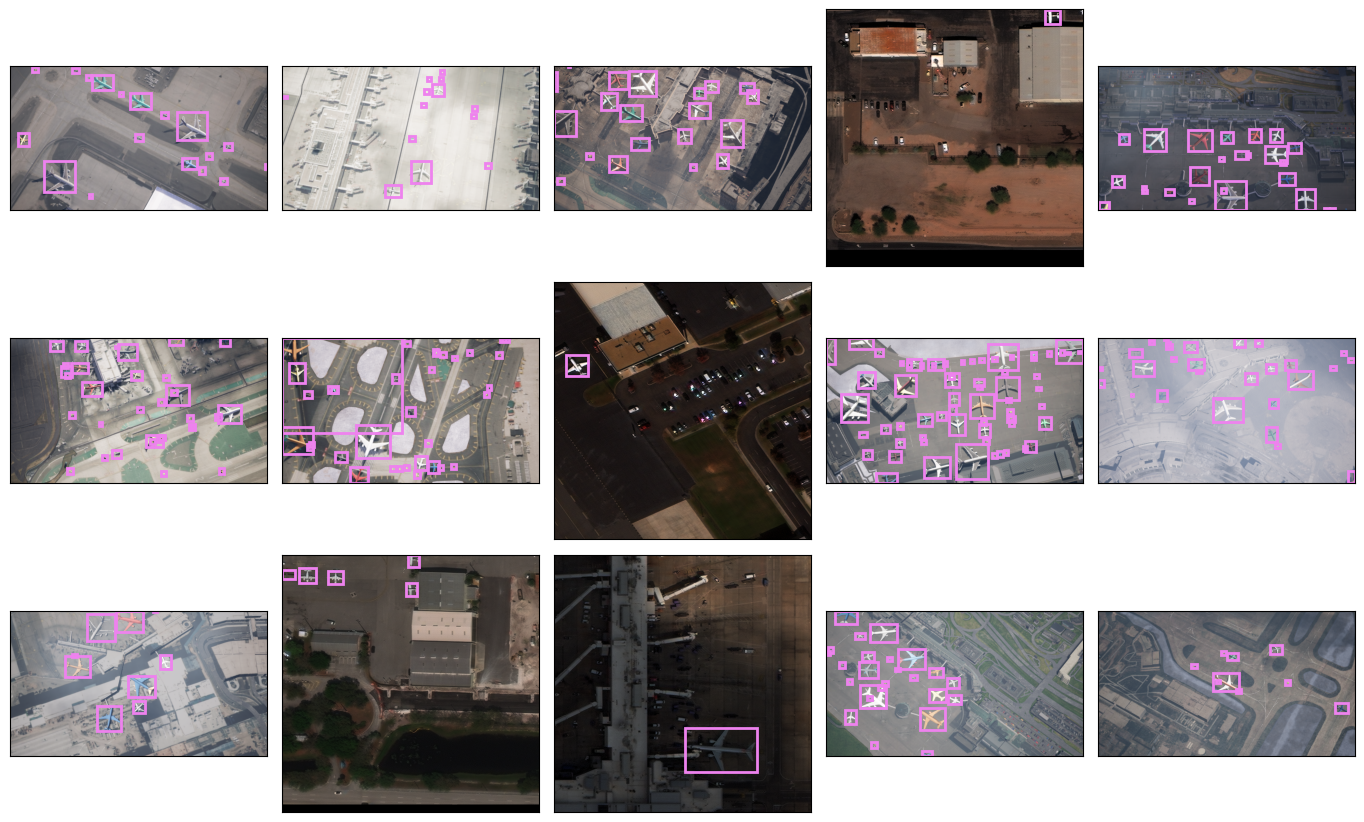

In [28]:
dataset.show_batch(15);

In [29]:
dataset.data_distribution_table()

,Label,Count
0,Airplane,578823


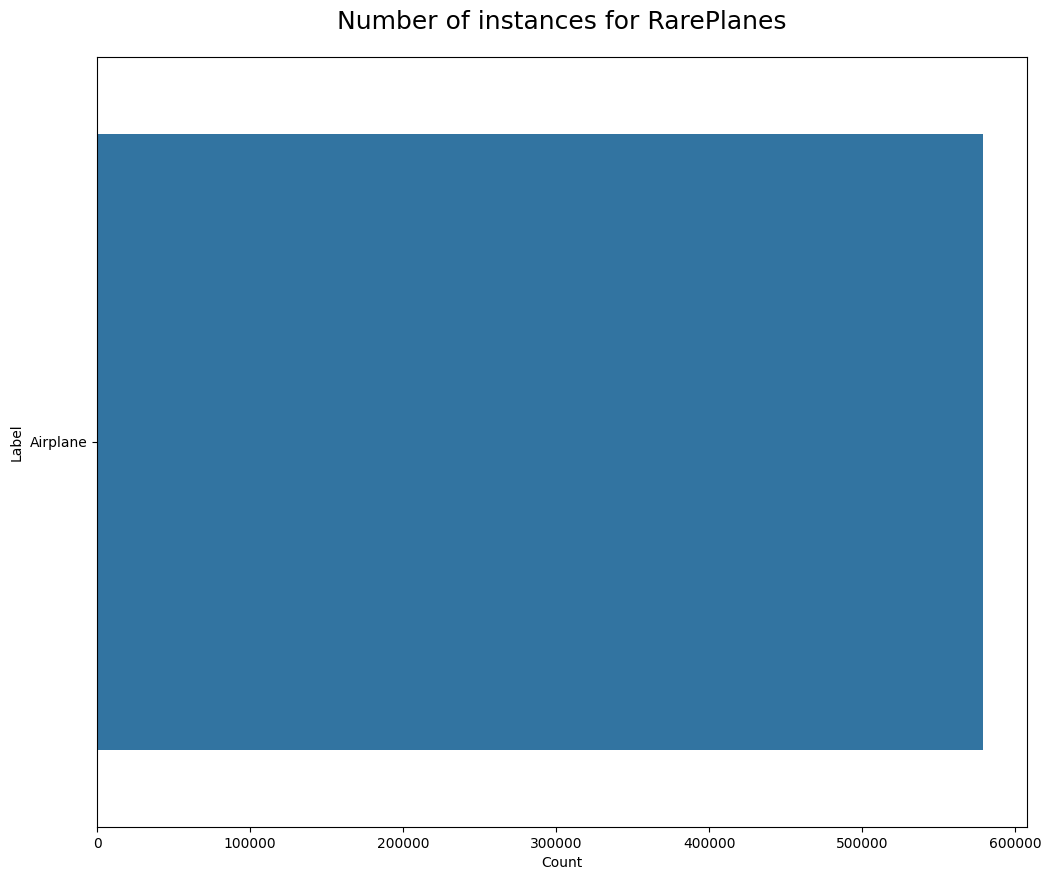

In [30]:
dataset.data_distribution_barchart();

## Load train data

In [ ]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/RarePlanes/",
    "csv_file": "./data/RarePlanes/rare_planes_train.csv",
    "imagery": "all", # can be replaced by real or synthetic
    "selection": "rgb",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}
train_dataset = RarePlanesDataset(train_dataset_config)

print(f"Total number of train images: {len(train_dataset)}")

Total number of train images: 35115


## Create the model

In [ ]:
epochs = 5
model_directory = "./data/experiments/RarePlanes/"
model_config = {
    "num_classes": 2,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}

model = FasterRCNN(model_config)
model.prepare()

## Start the training

In [11]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
)

2026-04-01 13:02:48,209 INFO Starting training.
training: 100%|██████████| 4390/4390 [1:08:07<00:00,  1.07it/s]
2026-04-01 14:10:56,098 INFO epoch: 1, time: 4088, loss:  0.31462
testing on train set: 100%|██████████| 4390/4390 [39:29<00:00,  1.85it/s]
2026-04-01 14:56:52,248 INFO map:0.7610350847244263, map_50:0.9386663436889648, map_75:0.8599197864532471, map_small:0.6867939233779907, map_medium:0.9437959790229797, map_large:0.7073558568954468, mar_1:0.057073842734098434, mar_10:0.46024951338768005, mar_100:0.7893301844596863, mar_small:0.7285566926002502, mar_medium:0.9611732363700867, mar_large:0.7535728812217712, map_per_class:0.7610350847244263, mar_100_per_class:0.7893301844596863, classes:1.0
training: 100%|██████████| 4390/4390 [1:18:00<00:00,  1.07s/it]
2026-04-01 16:14:53,214 INFO epoch: 2, time: 4681, loss:  0.23863
testing on train set: 100%|██████████| 4390/4390 [1:03:02<00:00,  1.16it/s]
2026-04-01 17:24:23,284 INFO map:0.7869681119918823, map_50:0.9475818872451782, map_7

0.1813106067123261

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 8,
    "shuffle": False,
    "data_dir": "./data/RarePlanes/",
    "csv_file": "./data/RarePlanes/rare_planes_val.csv",
    "imagery": "all",
    "selection": "rgb",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}

test_dataset = RarePlanesDataset(test_dataset_config)
print(f"Total number of test images: {len(test_dataset)}")

model = FasterRCNN(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/experiments/RarePlanes/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

Total number of test images: 11705


2026-04-02 06:49:26,480 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/RarePlanes/checkpoint.pth.tar
2026-04-02 06:49:26,930 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/RarePlanes/checkpoint.pth.tar at epoch 6
testing on test set: 100%|██████████| 1464/1464 [06:22<00:00,  3.82it/s]


[{'map': 0.803392231464386,
  'map_50': 0.9482644200325012,
  'map_75': 0.8952069282531738,
  'map_small': 0.7371450662612915,
  'map_medium': 0.9602523446083069,
  'map_large': 0.7356744408607483,
  'mar_1': 0.05781564861536026,
  'mar_10': 0.47146177291870117,
  'mar_100': 0.8249905705451965,
  'mar_small': 0.7728224396705627,
  'mar_medium': 0.9736235737800598,
  'mar_large': 0.785804808139801,
  'map_per_class': 0.803392231464386,
  'mar_100_per_class': 0.8249905705451965,
  'classes': 1.0}]

## Predictions

2026-04-02 06:58:55,002 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/RarePlanes/checkpoint.pth.tar
2026-04-02 06:58:55,434 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/RarePlanes/checkpoint.pth.tar at epoch 6


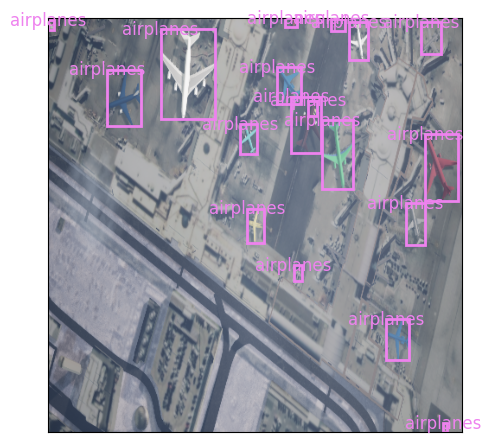

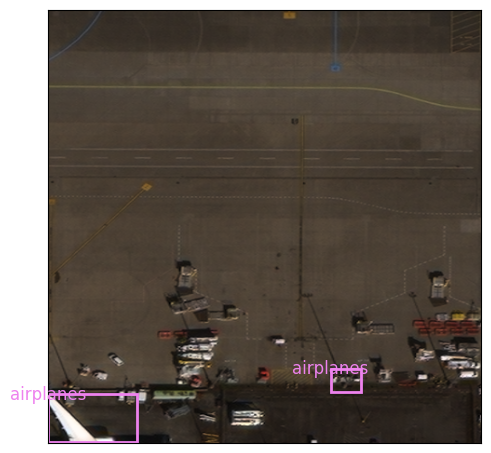

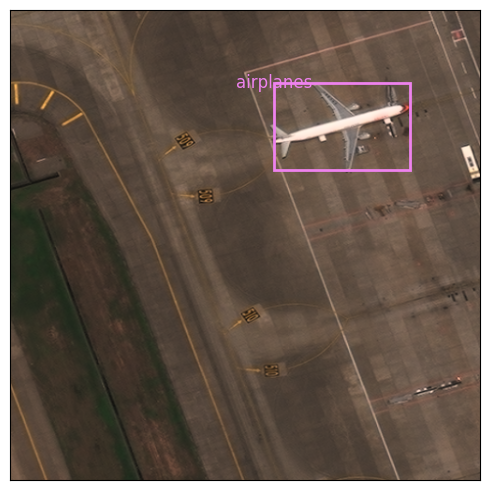

In [ ]:
model_config = {
    "num_classes": 2,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}
model = FasterRCNN(model_config)
model.prepare()

model_path = "./data/experiments/RarePlanes/checkpoint.pth.tar"
labels = ["no-data", "airplanes"]
transform = Resize()
model.load_model(model_path)

image = image_loader("./data/RarePlanes/synthetic/train/images/LosAngeles_Airport_0_0_449_23313.png")[:,:,:3]
fig = model.detect_objects(image, labels, transform)

image = image_loader("./data/RarePlanes/real/train/PS-RGB_tiled/4_1040010019345B00_tile_821.png")
fig = model.detect_objects(image, labels, transform)

image = image_loader("./data/RarePlanes/real/test/PS-RGB_tiled/126_104001000C4AEE00_tile_1551.png")
fig = model.detect_objects(image, labels, transform)